# 09 – Comprendre le modèle de l'intérieur

Au notebook 06, on a utilisé `HistGradientBoostingClassifier` un peu comme une boîte noire : `fit`, `predict_proba`, et ça marche. Ici, on **ouvre la boîte**, comme dans le projet 13, mais sur la zone méditerranéenne.

Fil rouge : **Martigues, le 16 juillet 2025**. Il y a bien eu un feu ce jour-là, et c'était l'un des jours les plus risqués du test selon le modèle. On va comprendre *d'où sort ce chiffre*.

**Au programme :**
1. la brique de base : **un arbre de décision**, qu'on dessine et qu'on suit à la main ;
2. le **boosting** : comment 500 arbres s'additionnent, avec une version « faite main » en 10 lignes ;
3. ce que le modèle a appris : les **courbes de dépendance partielle** ;
4. expliquer **une** prédiction : un simulateur « et si… ? » et la contribution de chaque variable.

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import average_precision_score

sauvegarde = joblib.load("../data/processed/modele_2016_2022.joblib")
modele, FEATURES, REGLAGES = sauvegarde["modele"], sauvegarde["features"], sauvegarde["reglages"]

df = pd.read_parquet("../data/processed/features_med.parquet", columns=["code", "jour", "feu"] + FEATURES)
communes = pd.read_csv("../data/processed/communes_med.csv", dtype={"code": str})
df["annee"] = df["jour"].dt.year

# comme au notebook 06 : tous les feux + 10 % des non-feux, avec un poids de 10
hasard = np.random.default_rng(42)
train = df[(df["annee"] <= 2020) & ((df["feu"] == 1) | (hasard.random(len(df)) < 0.10))]
poids = np.where(train["feu"] == 1, 1, 10)
valid = df[df["annee"].between(2021, 2022)]

# notre fil rouge
fil = df[(df["code"] == "13056") & (df["jour"] == "2025-07-16")]
fil[["jour", "feu", "temp_max", "vent_moy", "humidite_moy", "humidite_sol", "jours_sans_pluie",
     "bilan_hydrique_30j", "feux_commune_365j", "taux_feu_commune"]]

,jour,feu,temp_max,vent_moy,humidite_moy,humidite_sol,jours_sans_pluie,bilan_hydrique_30j,feux_commune_365j,taux_feu_commune
4920422,2025-07-16,1,32.400002,36.360001,37.400002,0.174,58,-226.199997,20.0,0.046081


On recharge le **modèle sauvegardé** au notebook 06 (entraîné sur 2016-2022) : pas besoin de le réentraîner.

Ce jour-là : 32 °C, un **vent moyen de 36 km/h** sur la journée (c'est beaucoup pour une moyenne sur 24 h : du mistral), un air sec (37 % d'humidité), un sol très sec (SWI 0,17), **58 jours sans pluie** et un bilan hydrique de −226 mm sur 30 jours. Et une commune qui a déjà connu **20 jours avec feu** dans l'année écoulée (taux historique 4,6 % des jours).

## Partie 1 – Un arbre de décision

### Leçon 1 – Comment un arbre choisit ses questions
Un arbre pose des questions oui/non (« `humidite_sol` ≤ 0,25 ? »). Pour choisir chaque question, l'algorithme :
1. essaie **toutes** les variables et **tous** les seuils possibles ;
2. pour chacun, coupe les données en deux groupes ;
3. garde la coupure qui donne les groupes les plus **« purs »** (l'un avec beaucoup de feux, l'autre avec très peu) ;
4. recommence dans chaque groupe, jusqu'à la profondeur maximale.

Personne ne lui dit que la sécheresse compte : il le **découvre** dans les données.

On entraîne un seul petit arbre, limité à **3 niveaux de questions** (8 feuilles au maximum), sur l'échantillon pondéré 2016-2020 :

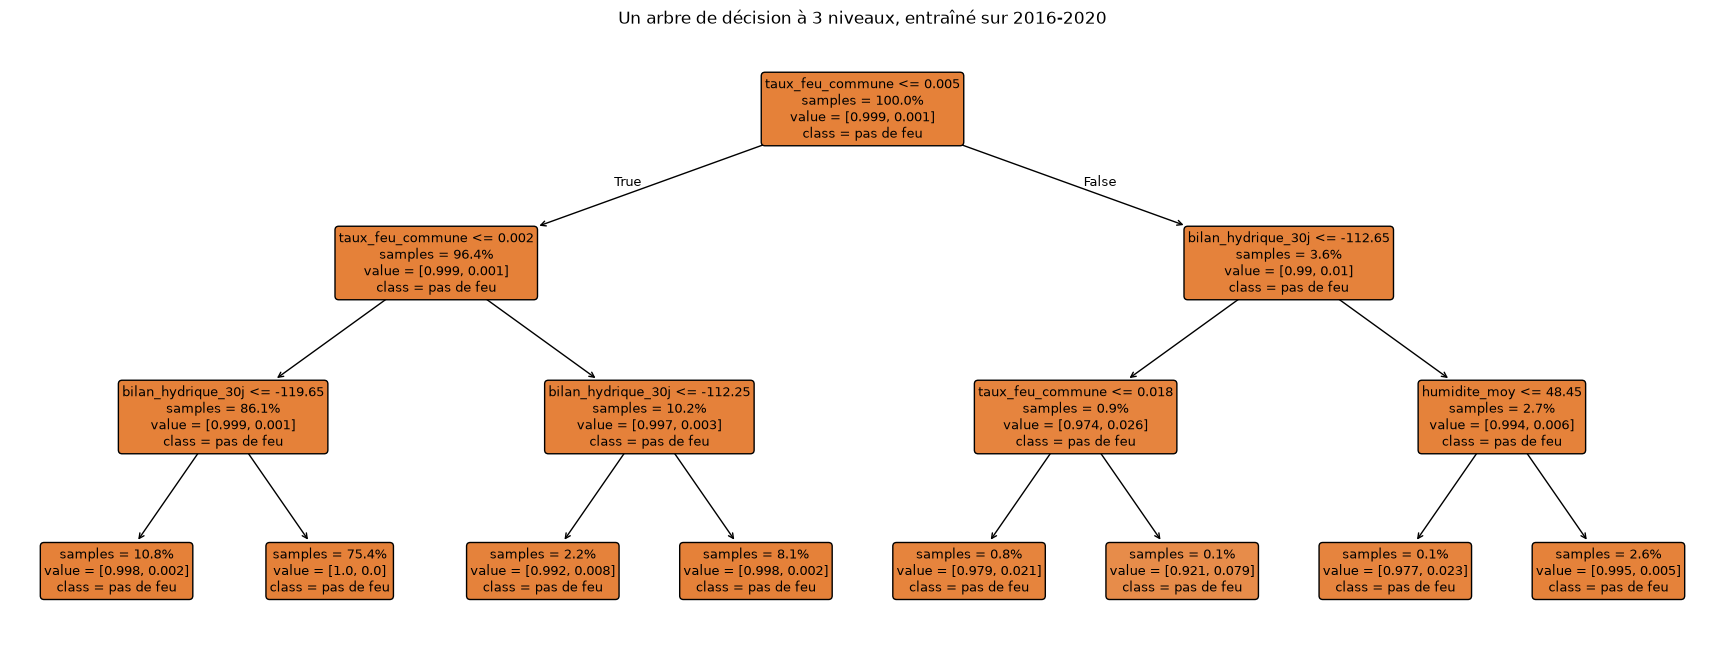

In [2]:
arbre = DecisionTreeClassifier(max_depth=3, min_samples_leaf=500, random_state=42)
arbre.fit(train[FEATURES], train["feu"], sample_weight=poids)

plt.figure(figsize=(22, 8))
plot_tree(arbre, feature_names=FEATURES, class_names=["pas de feu", "feu"],
          filled=True, proportion=True, impurity=False, rounded=True, fontsize=9)
plt.title("Un arbre de décision à 3 niveaux, entraîné sur 2016-2020")
plt.show()

**Comment lire chaque boîte :**
- la 1ʳᵉ ligne est la **question** (flèche de gauche = oui, flèche de droite = non) ;
- `samples` = la part (pondérée) des lignes qui arrivent dans cette boîte ;
- `value` = [part sans feu, part avec feu] ;
- `class` = la réponse majoritaire, toujours « pas de feu » ! Même dans la feuille la plus dangereuse, l'immense majorité des jours n'ont pas de feu. C'est pour ça qu'avec des événements rares, on utilise la **probabilité** (la part de feux dans la feuille), qui permet de **classer** les situations, et pas la classe majoritaire.

Un tableau des **feuilles** est plus parlant :

In [3]:
feuille = arbre.apply(train[FEATURES])          # numéro de la feuille où tombe chaque ligne
feuilles = (pd.DataFrame({"feuille": feuille, "feu": train["feu"].values, "poids": poids})
            .assign(feux_ponderes=lambda d: d["feu"] * d["poids"])
            .groupby("feuille").agg(jours=("poids", "sum"), jours_avec_feu=("feu", "sum"), fp=("feux_ponderes", "sum")))
feuilles["taux"] = feuilles["fp"] / feuilles["jours"]
feuilles = feuilles.drop(columns="fp").sort_values("taux")
feuilles.style.format({"jours": "{:,.0f}", "taux": "{:.2%}"})

,jours,jours_avec_feu,taux
feuille,,,
4,"4,851,600",2200,0.05%
3,"684,193",1363,0.20%
7,"511,206",1036,0.20%
14,"158,877",767,0.48%
6,"131,258",1018,0.78%
10,"45,416",966,2.13%
13,"6,447",147,2.28%
11,"4,048",318,7.86%


`jours` est le nombre de jours **réels** représentés (somme des poids) : chaque non-feu de l'échantillon en représente 10.

### Suivre notre fil rouge dans l'arbre
`decision_path` donne la liste des boîtes traversées. Pour chacune, on lit dans la structure interne de l'arbre (`arbre.tree_`) la variable et le seuil testés :

In [4]:
x = fil[FEATURES]
chemin = arbre.decision_path(x).indices
structure = arbre.tree_

for noeud in chemin:
    if structure.children_left[noeud] == -1:        # -1 = pas d'enfant → c'est une feuille
        print(f"→ FEUILLE : {structure.value[noeud][0][1]:.1%} de jours avec feu parmi les exemples d'entraînement")
    else:
        variable = FEATURES[structure.feature[noeud]]
        seuil = structure.threshold[noeud]
        valeur = x[variable].iloc[0]
        print(f"{variable} = {valeur:.3f}  {'≤' if valeur <= seuil else '>'} {seuil:.3f}")

taux_feu_commune = 0.046  > 0.005
bilan_hydrique_30j = -226.200  ≤ -112.650
taux_feu_commune = 0.046  > 0.018
→ FEUILLE : 7.9% de jours avec feu parmi les exemples d'entraînement


Martigues ce jour-là passe par : commune à l'historique très chargé (taux > 0,5 %, puis > 1,8 %) → végétation desséchée (bilan hydrique < −113 mm) → feuille la plus dangereuse de l'arbre : **7,9 %** de jours avec feu, soit ≈ 65 fois le taux moyen.

Remarque : la toute première question de l'arbre porte sur l'**historique de la commune**, pas sur la météo. Avec 3 505 communes dont la plupart brûlent très rarement, savoir *où* trie le plus de lignes d'un coup ; la sécheresse départage ensuite les jours.

**Limite :** un arbre de 3 niveaux n'a que 8 réponses possibles. Tous les jours qui tombent dans la même feuille reçoivent **exactement** la même probabilité. Pour être plus fin, on pourrait faire un arbre plus profond… mais il apprendrait par cœur (surapprentissage). D'où l'idée du boosting.

## Partie 2 – Le boosting : des centaines de petits arbres qui se corrigent

### Leçon 2 – Le principe
1. On part d'une prédiction **identique pour tous** : le taux moyen de feu (≈ 0,12 %).
2. Pour chaque ligne, on calcule l'**erreur** = vérité (0 ou 1) − prédiction actuelle.
3. Un **nouvel arbre** est entraîné à **prédire ces erreurs** : *« où est-ce qu'on se trompe encore ? »*
4. On ajoute sa correction **multipliée par un petit facteur** (le `learning_rate`) : chaque arbre ne fait qu'un petit pas prudent.
5. On recommence : le 2ᵉ arbre corrige ce que le 1ᵉʳ a raté, etc.

C'est le « **gradient** » de gradient boosting : l'erreur indique dans quelle direction corriger, comme une pente qu'on descend pas à pas.

### Le faire nous-mêmes, en 10 lignes
Version **simplifiée** à la main : des arbres de **régression** (`DecisionTreeRegressor`, qui prédit un nombre) entraînés sur les erreurs, avec les mêmes poids que d'habitude. Compte ≈ 1 minute.

In [5]:
X_tr, y_tr = train[FEATURES], train["feu"].values
X_va, y_va = valid[FEATURES], valid["feu"].values

pas = 0.1
depart = np.average(y_tr, weights=poids)        # le vrai taux moyen (≈ 0,12 %)
pred_tr = np.full(len(X_tr), depart)
pred_va = np.full(len(X_va), depart)

suivi = []
for i in range(1, 61):
    erreur = y_tr - pred_tr                                    # étape 2 : les erreurs
    petit_arbre = DecisionTreeRegressor(max_leaf_nodes=15, min_samples_leaf=5000, random_state=42)
    petit_arbre.fit(X_tr, erreur, sample_weight=poids)         # étape 3 : un arbre qui prédit les erreurs
    pred_tr = pred_tr + pas * petit_arbre.predict(X_tr)        # étape 4 : on corrige un peu
    pred_va = pred_va + pas * petit_arbre.predict(X_va)
    if i in [1, 2, 5, 10, 20, 40, 60]:
        suivi.append({"arbres": i, "PR-AUC validation": round(average_precision_score(y_va, pred_va), 4)})

pd.DataFrame(suivi)

,arbres,PR-AUC validation
0,1,0.0097
1,2,0.0123
2,5,0.0145
3,10,0.0160
4,20,0.0172
5,40,0.0172
6,60,0.0176


Avec **1 seul arbre**, la PR-AUC est faible (≈ 0,010) ; elle progresse à chaque arbre ajouté : 0,015 à 5 arbres, 0,016 à 10 (le niveau de la baseline lissée), **0,0176 à 60 arbres**. Notre version « maison » en 10 lignes **bat déjà la baseline** ! Le vrai modèle (500 arbres, réglages fins, log-odds) monte à 0,023.

**Ce que fait en plus `HistGradientBoostingClassifier` :**
- il corrige des **log-odds** (une échelle de −∞ à +∞) puis les reconvertit en probabilité avec une courbe en S (la **sigmoïde**) : la prédiction reste entre 0 et 1, et les événements rares sont mieux traités ;
- **« Hist »** : il range d'abord chaque variable en 255 tranches (un **histogramme**) au lieu de tester chaque valeur exacte comme seuil → beaucoup plus rapide sur des centaines de milliers de lignes.

### Le vrai modèle, arbre par arbre
`staged_predict_proba` donne la prédiction après 1 arbre, 2 arbres… jusqu'au dernier. On compare notre fil rouge à deux jours très différents :

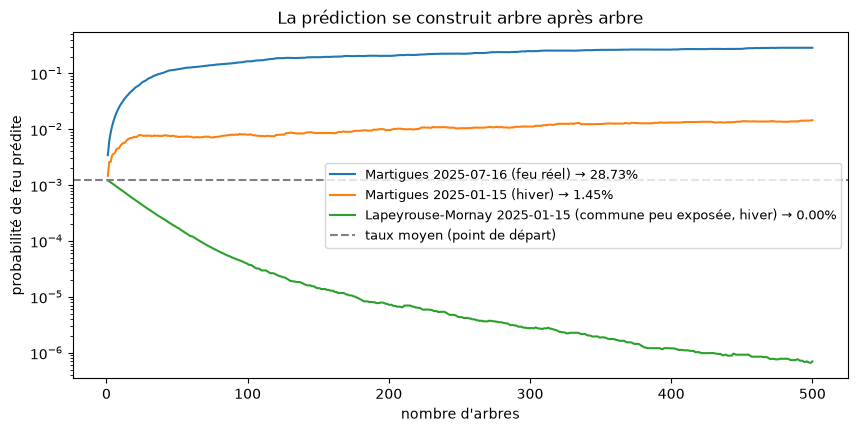

In [6]:
nom = dict(zip(communes["code"], communes["nom"]))
exemples = {
    f"{nom['13056']} 2025-07-16 (feu réel)": fil,
    f"{nom['13056']} 2025-01-15 (hiver)": df[(df["code"] == "13056") & (df["jour"] == "2025-01-15")],
    f"{nom['26155']} 2025-01-15 (commune peu exposée, hiver)": df[(df["code"] == "26155") & (df["jour"] == "2025-01-15")],
}

plt.figure(figsize=(10, 4.5))
for etiquette, ligne in exemples.items():
    trajectoire = [p[0, 1] for p in modele.staged_predict_proba(ligne[FEATURES])]
    plt.plot(range(1, len(trajectoire) + 1), trajectoire, label=f"{etiquette} → {trajectoire[-1]:.2%}")
plt.axhline(np.average(y_tr, weights=poids), color="grey", linestyle="--", label="taux moyen (point de départ)")
plt.xlabel("nombre d'arbres")
plt.ylabel("probabilité de feu prédite")
plt.yscale("log")
plt.title("La prédiction se construit arbre après arbre")
plt.legend(fontsize=9)
plt.show()

`plt.yscale("log")` : échelle **logarithmique**, pour voir sur le même graphique des probabilités de 0,001 % et de 30 %.

**Lecture :** les trois courbes partent du même point (le taux moyen, ≈ 0,12 %).
- **Martigues le 16 juillet** : presque chaque arbre ajoute « un peu plus de risque », car plusieurs signaux s'additionnent (historique, vent, sécheresse) → **29 %**, soit ≈ 240 fois le taux moyen.
- **Lapeyrouse-Mornay en hiver** (village agricole de la Drôme, sans historique de feu) : les arbres font **baisser** le risque, arbre après arbre, jusqu'à **0,0001 %**.
- **Martigues en hiver** : la saison pousse vers le bas, mais l'historique très chargé de la commune pousse vers le haut. Résultat ≈ 1,5 %, plus de 10 fois la moyenne, même en janvier !

Au bout du compte, le modèle n'est **rien d'autre qu'une somme de petites règles pondérées** (nombre d'arbres × nombre de feuilles).

## Partie 3 – Ce que le modèle a appris : la dépendance partielle

### Leçon 3 – Rappel
*« Si je fais varier **une seule** variable, toutes les autres restant comme dans la réalité, comment évolue le risque prédit en moyenne ? »* On **force** une valeur dans des milliers de lignes réelles, on prédit, on fait la moyenne, et on recommence pour chaque valeur.

Échantillon de 4 000 jours pris **sur toute l'année** 2016-2022. `.astype(float)` : l'outil refuse les colonnes d'entiers. ⏱️ ≈ 30 s.

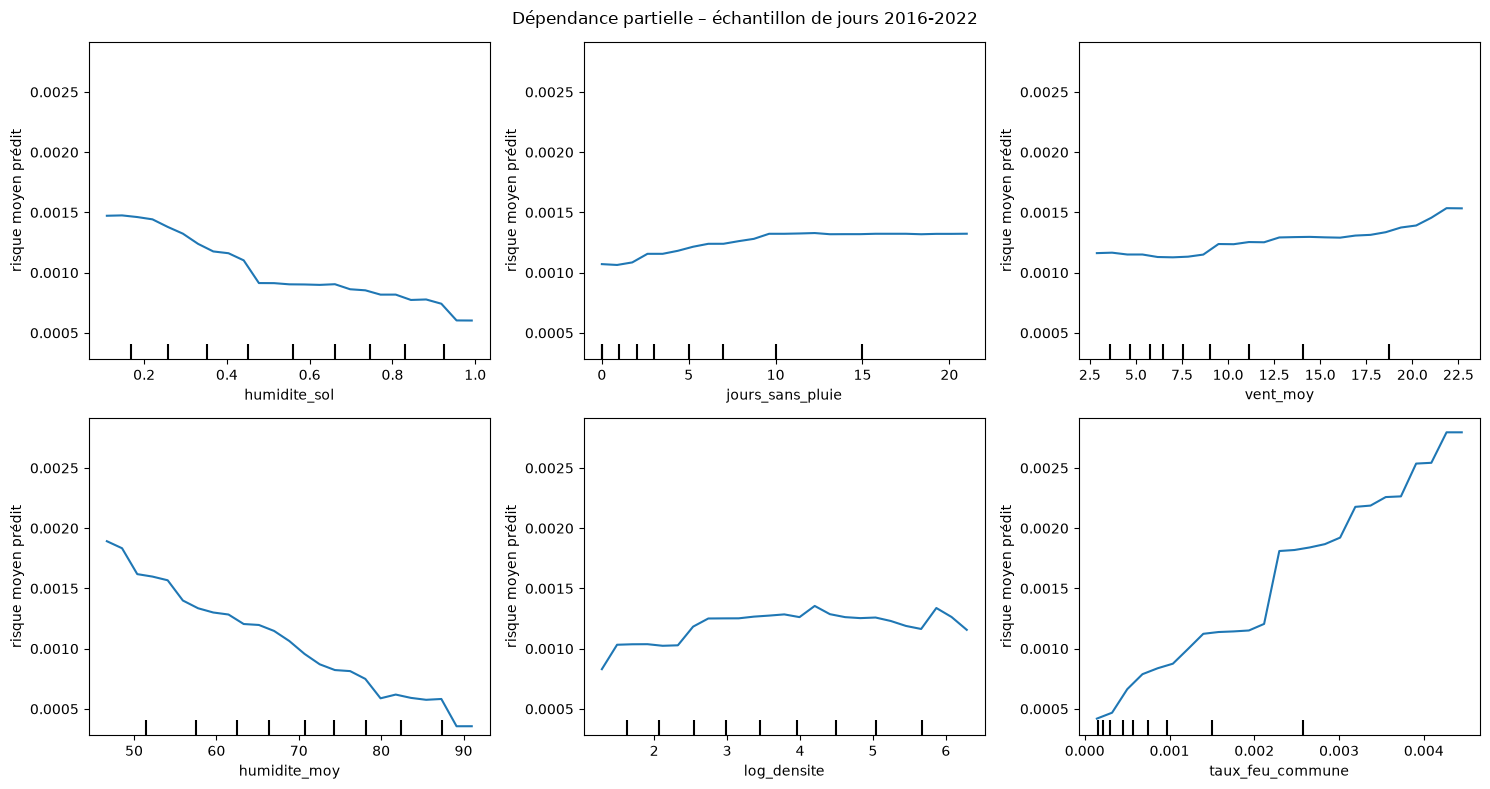

In [7]:
echantillon = df[df["annee"] <= 2022].sample(4000, random_state=42)[FEATURES].astype(float)

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
PartialDependenceDisplay.from_estimator(
    modele, echantillon,
    features=["humidite_sol", "jours_sans_pluie", "vent_moy", "humidite_moy", "log_densite", "taux_feu_commune"],
    response_method="predict_proba", method="brute", grid_resolution=25, ax=ax.ravel(),
)
for a in ax.ravel():
    a.set_ylabel("risque moyen prédit")
plt.suptitle("Dépendance partielle – échantillon de jours 2016-2022")
plt.tight_layout()
plt.show()

Les petits traits en bas de chaque graphique montrent où se trouvent les données réelles : là où il y en a peu, la courbe est moins fiable.

**Ce qu'on lit :**
- **historique de la commune** (`taux_feu_commune`) : l'effet le plus fort, le risque moyen est multiplié par ≈ 6 entre une commune qui ne brûle jamais et une qui brûle souvent ;
- **humidité de l'air** : plus l'air est sec, plus le risque monte (×5 entre 90 % et 47 %) ;
- **humidité des sols** : relation régulière, le risque est multiplié par ≈ 2,5 entre un sol saturé et un sol très sec ;
- **vent** : le risque augmente avec le vent moyen de la journée, surtout au-delà de ≈ 17 km/h ;
- **jours sans pluie** et **densité** : effets modestes « toutes choses égales par ailleurs », car d'autres variables portent déjà l'information (l'humidité des sols résume la sécheresse ; l'historique de la commune résume en partie la présence humaine). C'est le piège des variables corrélées, déjà vu au notebook 06.

Les courbes sont **en escalier** : c'est la signature des arbres, qui raisonnent par seuils.

⚠️ **Rappel :** « toutes choses égales par ailleurs » est parfois irréaliste quand les variables sont **corrélées** (chaleur, humidité de l'air et du sol, saison…). Une courbe de dépendance partielle décrit **comment le modèle réagit**, pas forcément **comment le monde fonctionne**.

## Partie 4 – Expliquer une prédiction

### Un simulateur « et si… ? »
On reprend la ligne du fil rouge et on modifie une ou deux variables. `**changements` permet de passer autant de modifications qu'on veut, sous la forme `variable=valeur`.

In [8]:
def et_si(**changements):
    ligne = fil[FEATURES].copy()
    for variable, valeur in changements.items():
        ligne[variable] = valeur
    return modele.predict_proba(ligne)[0, 1]

scenarios = {
    "la réalité": {},
    "vent faible (8 km/h)": {"vent_moy": 8, "vent_fort": 0},
    "sol humide (SWI 0,6)": {"humidite_sol": 0.6, "humidite_sol_7j": 0.6},
    "il a plu hier (2 jours sans pluie)": {"jours_sans_pluie": 2, "pluie_7j": 15},
    "commune sans historique de feu": {"feux_commune_365j": 0, "taux_feu_commune": 0.0005},
    "un dimanche": {"jour_semaine": 6, "week_end": 1},
}
pd.DataFrame({"risque prédit": {nom: f"{et_si(**chg):.2%}" for nom, chg in scenarios.items()}})

,risque prédit
la réalité,28.73%
vent faible (8 km/h),16.75%
"sol humide (SWI 0,6)",10.36%
il a plu hier (2 jours sans pluie),13.94%
commune sans historique de feu,1.94%
un dimanche,28.87%


**Lecture :** l'**historique de la commune** est le levier n°1 : sans lui, le risque tombe de 29 % à **1,9 %** (÷15). Viennent ensuite l'**humidité des sols** (un sol humide → 10 %), une **pluie récente** (14 %) et le **vent** (vent faible → 17 %). Le jour de la semaine ne change rien. Les effets ne s'additionnent pas simplement : c'est la **combinaison** historique × sécheresse × vent qui fait les 29 %, exactement ce que les arbres savent capturer.

**À toi de jouer :** ajoute un scénario « village de montagne » (`log_densite=1.5`) et un scénario « air très sec » (`humidite_moy=25`). Lequel fait le plus bouger le risque ?

### Quelle variable a « poussé » la prédiction ?
Pour chaque variable, on la **remplace par sa valeur typique d'un jour d'été** (médiane de juillet-août), toutes les autres restant celles du fil rouge, et on regarde de combien le risque **change**.

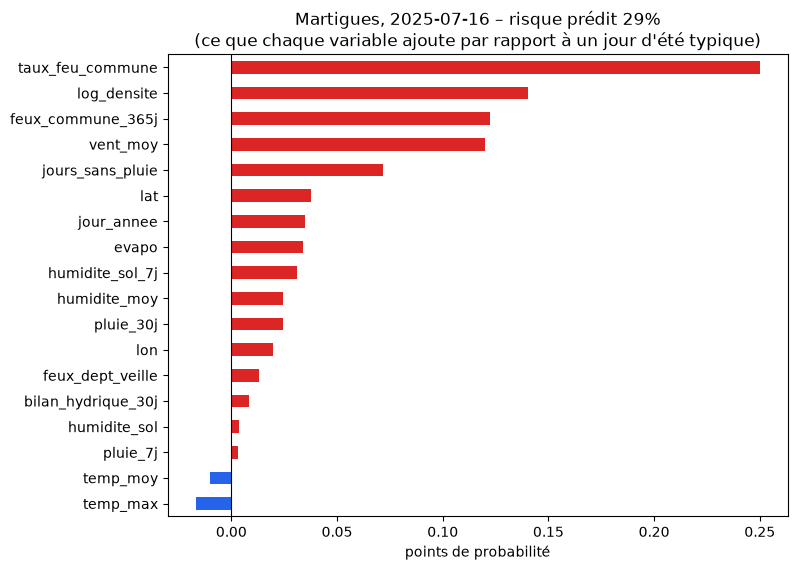

In [9]:
typique = df[df["jour"].dt.month.isin([7, 8])][FEATURES].median()
risque_reel = et_si()

contributions = pd.Series({v: risque_reel - et_si(**{v: typique[v]}) for v in FEATURES}).sort_values()
gros = contributions[contributions.abs() > 0.003]
gros.plot(kind="barh", figsize=(8, 6), color=["#2563eb" if v < 0 else "#dc2626" for v in gros],
          title=f"{nom['13056']}, 2025-07-16 – risque prédit {risque_reel:.0%}\n(ce que chaque variable ajoute par rapport à un jour d'été typique)")
plt.xlabel("points de probabilité")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

- en **rouge**, les variables qui **augmentaient** le risque ce jour-là par rapport à un jour d'été typique ;
- en **bleu**, celles qui le **diminuaient**.

Pour Martigues le 16 juillet 2025, par rapport à un jour d'été typique : l'**historique chargé** de la commune (taux et feux sur 365 jours), sa **densité de population**, le **vent** et les **58 jours sans pluie** expliquent l'essentiel du risque.

Seules les **températures** le font très légèrement baisser. C'est le même artefact que dans le projet 13 : à humidité et sécheresse données, le modèle n'attribue pas de risque supplémentaire à la chaleur elle-même, car son effet passe déjà par l'évapotranspiration, l'humidité de l'air et des sols, qui en dépendent. Remplacer une seule variable crée une situation un peu artificielle : on lit ces barres avec du bon sens physique.

> Pour aller plus loin : la méthode de référence s'appelle **SHAP** (bibliothèque `shap`). Elle répartit la prédiction entre les variables de façon rigoureuse (les contributions s'additionnent exactement). Notre méthode « remplacer par une valeur typique » en est une version simplifiée.

## Récap

1. **Un arbre** choisit lui-même ses questions en cherchant les coupures qui séparent le mieux feux et non-feux ; lisible mais grossier.
2. **Le boosting** additionne des centaines de petits arbres, chacun entraîné sur les **erreurs** des précédents, avec un petit pas (`learning_rate`).
3. **Dépendance partielle** : comment le risque évolue avec une variable, en escalier.
4. **Expliquer une prédiction** : simulateur « et si » et contributions par rapport à un jour typique.